# Кто оформит карту в следующем году

Продолжение проекта [bank-card-analysis](https://github.com/syulzhins/bank-card-analysis). Там я на SQL выяснил, что карта не делает клиента активнее, а берут её клиенты, которые уже и так обеспечены. Сегмент «кому предлагать карту» я тогда выделил ручным правилом по порогам.

Здесь пробую сделать то же самое моделью: по поведению клиента за **1997 год** предсказать, оформит ли он карту в **1998**. Модель видит только прошлое, поэтому проверка честная: так её можно было бы применить в реальном банке.

План:
1. Собрать одну строку на клиента с признаками за 1997 год.
2. Посмотреть на данные: чем будущие держатели карт отличаются от остальных.
3. Обучить логистическую регрессию и случайный лес, сравнить по ROC-AUC.
4. Сравнить модель с моим правилом из SQL-проекта на одинаковом числе клиентов.

Данные: датасет Berka (чешский банк, 1993–1998), CSV лежат в папке `data/`.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from sklearn.inspection import permutation_importance

DATA = "../data/"
IMG = "../images/"

# один стиль для всех графиков
CARD = "#2a78d6"     # оформили карту
NO_CARD = "#eb6834"  # не оформили
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## 1. Загрузка и очистка

Всё, что я нашёл в SQL-проекте, повторяю здесь:
- разделитель в CSV `;`, даты в формате YYMMDD;
- пустые значения записаны тремя способами: NULL, пустая строка и пробел;
- в `birth_number` у женщин к месяцу прибавлено 50, год = 1900 + YY.

In [5]:
clients = pd.read_csv(DATA + "client.csv", sep=";")
accounts = pd.read_csv(DATA + "account.csv", sep=";")
disp = pd.read_csv(DATA + "disp.csv", sep=";")
cards = pd.read_csv(DATA + "card.csv", sep=";")
loans = pd.read_csv(DATA + "loan.csv", sep=";")
districts = pd.read_csv(DATA + "district.csv", sep=";")
trans = pd.read_csv(DATA + "trans.csv", sep=";", low_memory=False)

print(len(trans), "транзакций")

1056320 транзакций


In [6]:
# даты
accounts["opened"] = pd.to_datetime(accounts["date"].astype(str), format="%y%m%d")
cards["issued"] = pd.to_datetime(cards["issued"].str[:6], format="%y%m%d")
loans["loan_date"] = pd.to_datetime(loans["date"].astype(str), format="%y%m%d")
trans["date"] = pd.to_datetime(trans["date"].astype(str), format="%y%m%d")

# пустые k_symbol: пробел и пустую строку считаем пропуском
trans["k_symbol"] = trans["k_symbol"].str.strip().replace("", np.nan)

# пол и дата рождения из birth_number
bn = clients["birth_number"].astype(str).str.zfill(6)
month = bn.str[2:4].astype(int)
clients["gender"] = np.where(month > 50, "F", "M")
clients["birth_date"] = pd.to_datetime(
    (1900 + bn.str[:2].astype(int)).astype(str) + "-"
    + (month - np.where(month > 50, 50, 0)).astype(str).str.zfill(2) + "-"
    + bn.str[4:6]
)

clients[["client_id", "gender", "birth_date"]].head()

,client_id,gender,birth_date
0,1,F,1970-12-13
1,2,M,1945-02-04
2,3,F,1940-10-09
3,4,M,1956-12-01
4,5,F,1960-07-03


## 2. Кого берём и что предсказываем

- Берём **владельцев счетов** (disp type = OWNER), у которых счёт открыт до 1997 года: так у всех есть полный 1997 год истории.
- Убираем тех, у кого карта уже была до 1998: им предлагать нечего.
- **Цель:** карта выдана в 1998 году (1 — да, 0 — нет).

In [7]:
owners = (disp[disp["type"] == "OWNER"]
          .merge(accounts[["account_id", "opened", "district_id", "frequency"]], on="account_id")
          .merge(clients[["client_id", "gender", "birth_date"]], on="client_id")
          .merge(cards[["disp_id", "issued"]], on="disp_id", how="left"))

df = owners[(owners["opened"] < "1997-01-01") & ~(owners["issued"] < "1998-01-01")].copy()
df["target"] = (df["issued"].dt.year == 1998).astype(int)

print(len(df), "клиентов,", df["target"].sum(), "оформили карту в 1998")
print(f"доля: {df['target'].mean():.1%}")

3176 клиентов, 292 оформили карту в 1998
доля: 9.2%


Классы несбалансированные: карту оформили примерно 9% клиентов. Поэтому accuracy здесь бесполезна: модель, которая всем говорит «не оформит», будет права в 91% случаев. Смотрю на ROC-AUC и на то, какую долю будущих держателей модель находит среди клиентов с самым высоким скором.

## 3. Признаки за 1997 год

Транзакции агрегирую до одной строки на счёт, так же как CTE `activity` в SQL-проекте. Дальше добавляю возраст, кредиты, данные района.

In [8]:
t97 = trans[trans["date"].dt.year == 1997]

activity = t97.groupby("account_id").agg(
    trans_per_month=("trans_id", lambda x: len(x) / 12),
    avg_balance=("balance", "mean"),
    min_balance=("balance", "min"),
)

# поступления в месяц
# расходы не беру: они почти равны поступлениям, и два одинаковых признака путают логистическую регрессию
activity["income_per_month"] = t97[t97["type"] == "PRIJEM"].groupby("account_id")["amount"].sum() / 12

# доля снятий наличными среди операций
is_cash = t97["operation"] == "VYBER"
activity["cash_share"] = is_cash.groupby(t97["account_id"]).mean()

# получает ли пенсию и платит ли за коммунальные услуги
activity["gets_pension"] = (t97["k_symbol"] == "DUCHOD").groupby(t97["account_id"]).any().astype(int)
activity["pays_household"] = (t97["k_symbol"] == "SIPO").groupby(t97["account_id"]).any().astype(int)

activity = activity.fillna(0).reset_index()
activity.head()

,account_id,trans_per_month,avg_balance,min_balance,income_per_month,cash_share,gets_pension,pays_household
0,1,5.333333,14099.793750,8800.6,4106.258333,0.390625,0,1
1,2,7.000000,43722.405952,25037.1,23464.833333,0.547619,0,1
2,3,2.083333,23092.900000,1000.0,4844.975000,0.320000,0,1
3,4,6.500000,20180.684615,13599.0,5637.066667,0.384615,1,1
4,5,1.500000,22244.094444,600.0,2995.908333,0.277778,1,1


In [9]:
df = df.merge(activity, on="account_id", how="left")

# возраст и «стаж» счёта на 1 января 1998
ref = pd.Timestamp("1998-01-01")
df["age"] = (ref - df["birth_date"]).dt.days / 365.25
df["account_years"] = (ref - df["opened"]).dt.days / 365.25
df["is_female"] = (df["gender"] == "F").astype(int)
df["monthly_statement"] = (df["frequency"] == "POPLATEK MESICNE").astype(int)

# кредит, выданный до 1998
loans_97 = loans[loans["loan_date"] < "1998-01-01"]
df["has_loan"] = df["account_id"].isin(loans_97["account_id"]).astype(int)

# есть ли у счёта второй пользователь (disponent)
df["has_disponent"] = df["account_id"].isin(disp.loc[disp["type"] == "DISPONENT", "account_id"]).astype(int)

# район: средняя зарплата и доля городского населения
dist = districts.rename(columns={"A1": "district_id", "A11": "district_salary", "A10": "district_urban_pct"})
df = df.merge(dist[["district_id", "district_salary", "district_urban_pct"]], on="district_id", how="left")

FEATURES = [
    "age", "is_female", "account_years", "monthly_statement",
    "trans_per_month", "income_per_month",
    "avg_balance", "min_balance", "cash_share",
    "gets_pension", "pays_household", "has_loan", "has_disponent",
    "district_salary", "district_urban_pct",
]

# у 4 клиентов не было ни одной операции в 1997, признаки по ним не посчитать, убираем
no_activity = df["trans_per_month"].isna()
print(no_activity.sum(), "клиентов без операций в 1997, убираем")
df = df[~no_activity].reset_index(drop=True)
print(len(df), "клиентов,", df[FEATURES].isna().sum().sum(), "пропусков в признаках")
df[FEATURES + ["target"]].describe().T.round(1)

4 клиентов без операций в 1997, убираем
3172 клиентов, 0 пропусков в признаках


,count,mean,std,min,25%,50%,75%,max
age,3172.0,44.3,17.3,15.1,29.6,43.5,57.3,80.0
is_female,3172.0,0.5,0.5,0.0,0.0,0.0,1.0,1.0
account_years,3172.0,2.8,1.3,1.0,1.6,2.6,4.2,5.0
monthly_statement,3172.0,0.9,0.3,0.0,1.0,1.0,1.0,1.0
trans_per_month,3172.0,6.0,1.5,0.2,5.2,5.9,6.8,11.6
income_per_month,3172.0,16300.6,14302.8,0.0,5756.7,11810.7,22099.8,78314.6
avg_balance,3172.0,35002.3,16183.4,-3187.7,21811.7,31819.1,44936.6,96172.1
min_balance,3172.0,17426.7,10106.1,-17030.4,11505.5,15547.4,22353.3,74742.9
cash_share,3172.0,0.4,0.1,0.1,0.4,0.4,0.5,1.0
gets_pension,3172.0,0.2,0.4,0.0,0.0,0.0,0.0,1.0


## 4. Чем будущие держатели карт отличаются

Сначала медианы по двум группам: медиана устойчивее к очень богатым клиентам, чем среднее.

In [10]:
df.groupby("target")[["age", "income_per_month", "avg_balance", "trans_per_month", "cash_share", "gets_pension"]].median().round(2)

,age,income_per_month,avg_balance,trans_per_month,cash_share,gets_pension
target,,,,,,
0,43.92,10612.01,29837.62,5.83,0.42,0.0
1,38.79,21685.88,48243.60,6.08,0.44,0.0


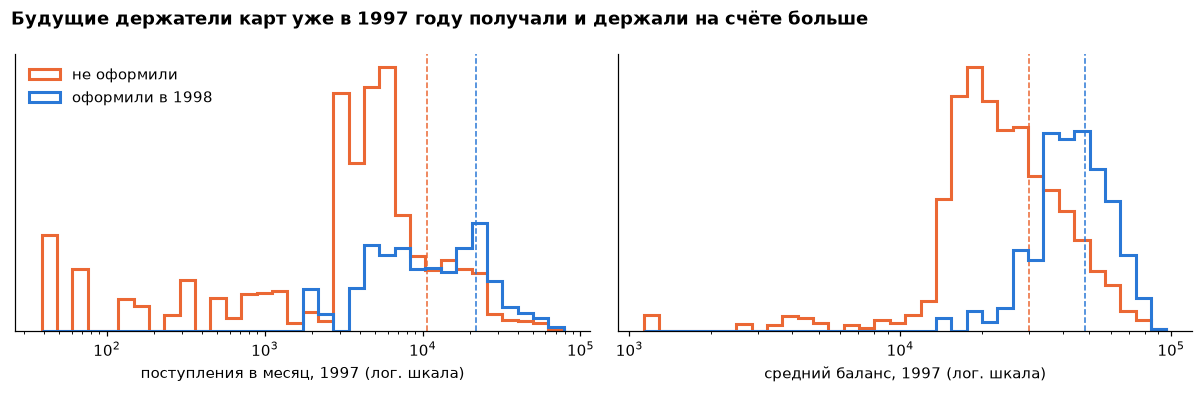

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

for ax, col, label in [(axes[0], "income_per_month", "поступления в месяц, 1997"),
                       (axes[1], "avg_balance", "средний баланс, 1997")]:
    data = df[df[col] > 0]
    bins = np.logspace(np.log10(data[col].min()), np.log10(data[col].max()), 35)
    for t, color, name in [(0, NO_CARD, "не оформили"), (1, CARD, "оформили в 1998")]:
        values = data.loc[data["target"] == t, col]
        # density=True: сравниваем форму, а не размер групп
        ax.hist(values, bins=bins, density=True, histtype="step", linewidth=2, color=color, label=name)
        ax.axvline(values.median(), color=color, linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_xlabel(label + " (лог. шкала)")
    ax.set_yticks([])

axes[0].legend(frameon=False)
fig.suptitle("Будущие держатели карт уже в 1997 году получали и держали на счёте больше", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(IMG + "01_income_balance.png")
plt.show()

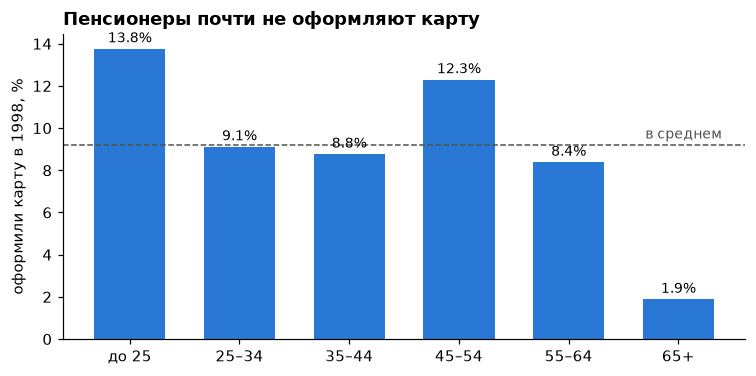

,mean,count
age_group,,
до 25,0.137667,523
25–34,0.091222,581
35–44,0.087719,570
45–54,0.123023,569
55–64,0.083885,453
65+,0.018908,476


In [12]:
# доля оформивших карту по возрастным группам
df["age_group"] = pd.cut(df["age"], bins=[0, 25, 35, 45, 55, 65, 100],
                         labels=["до 25", "25–34", "35–44", "45–54", "55–64", "65+"], right=False)
by_age = df.groupby("age_group", observed=True)["target"].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(by_age.index.astype(str), by_age["mean"] * 100, color=CARD, width=0.65)
for bar, v in zip(bars, by_age["mean"] * 100):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)
ax.axhline(df["target"].mean() * 100, color="#52514e", linestyle="--", linewidth=1)
ax.text(5.4, df["target"].mean() * 100 + 0.3, "в среднем", fontsize=9, color="#52514e", ha="right")
ax.set_ylabel("оформили карту в 1998, %")
ax.set_title("Пенсионеры почти не оформляют карту", loc="left", fontweight="bold")
fig.savefig(IMG + "02_by_age.png")
plt.show()

by_age

## 5. Модели

Делю клиентов на обучающую (75%) и тестовую (25%) выборки со стратификацией, чтобы доля оформивших была одинаковой. На обучающей сравниваю модели кросс-валидацией, тестовую трогаю только в конце.

- **Логистическая регрессия:** простая и интерпретируемая. Признаки в разных масштабах, поэтому перед ней StandardScaler.
- **Случайный лес:** ловит нелинейности, например что возраст влияет не линейно.

Обеим ставлю `class_weight="balanced"`, чтобы модель не игнорировала редкий класс.

In [13]:
X = df[FEATURES]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

models = {
    "логистическая регрессия": make_pipeline(
        StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "случайный лес": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=20, class_weight="balanced", random_state=42, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name}: ROC-AUC на кросс-валидации {scores.mean():.3f} ± {scores.std():.3f}")

логистическая регрессия: ROC-AUC на кросс-валидации 0.819 ± 0.026
случайный лес: ROC-AUC на кросс-валидации 0.801 ± 0.020


In [14]:
# обучаем на всей обучающей выборке и проверяем на тестовой
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    results[name] = proba
    print(f"{name}: ROC-AUC {roc_auc_score(y_test, proba):.3f}, "
          f"PR-AUC {average_precision_score(y_test, proba):.3f}")

print(f"для сравнения, PR-AUC случайного угадывания = доля класса = {y_test.mean():.3f}")

логистическая регрессия: ROC-AUC 0.796, PR-AUC 0.271
случайный лес: ROC-AUC 0.824, PR-AUC 0.311
для сравнения, PR-AUC случайного угадывания = доля класса = 0.092


## 6. Сравнение с ручным правилом из SQL-проекта

Правило то же, что в запросе 4: поступления и баланс не ниже нижней четверти держателей карт и нет проблемного кредита. Пороги считаю по обучающей выборке, а проверяю на тестовой.

Чтобы сравнение было честным, беру у модели ровно столько клиентов, сколько отбирает правило, и смотрю, у кого среди отобранных больше реальных будущих держателей.

In [15]:
# проблемный кредит: статус B или D (как в clean.loans.is_problem)
problem = loans_97.loc[loans_97["status"].isin(["B", "D"]), "account_id"]
problem_test = X_test.index.map(lambda i: df.loc[i, "account_id"]).isin(problem)

holders = X_train[y_train == 1]
min_income = holders["income_per_month"].quantile(0.25)
min_balance = holders["avg_balance"].quantile(0.25)

rule = ((X_test["income_per_month"] >= min_income)
        & (X_test["avg_balance"] >= min_balance)
        & ~problem_test)

n = rule.sum()
print(f"пороги: поступления от {min_income:,.0f}, баланс от {min_balance:,.0f}")
print(f"правило отбирает {n} из {len(X_test)} клиентов теста ({n / len(X_test):.0%})\n")

rows = [{"способ": "ручное правило", "отобрано": n,
         "из них оформили": y_test[rule].sum(),
         "precision": y_test[rule].mean(),
         "нашли держателей": y_test[rule].sum() / y_test.sum()}]

for name, proba in results.items():
    top = pd.Series(proba, index=X_test.index).nlargest(n).index
    rows.append({"способ": name, "отобрано": n,
                 "из них оформили": y_test[top].sum(),
                 "precision": y_test[top].mean(),
                 "нашли держателей": y_test[top].sum() / y_test.sum()})

comparison = pd.DataFrame(rows)
comparison.style.format({"precision": "{:.1%}", "нашли держателей": "{:.1%}"})

пороги: поступления от 12,750, баланс от 39,379
правило отбирает 227 из 793 клиентов теста (29%)



,способ,отобрано,из них оформили,precision,нашли держателей
0,ручное правило,227,46,20.3%,63.0%
1,логистическая регрессия,227,50,22.0%,68.5%
2,случайный лес,227,52,22.9%,71.2%


**Как читать таблицу.** Precision — какая доля отобранных клиентов действительно оформила карту, то есть насколько «точно» мы бы тратили коммуникацию. «Нашли держателей» (recall) — какую долю всех будущих держателей мы охватили.

### Кривая охвата

Если сортировать клиентов по скору модели и предлагать карту сверху вниз, какую долю будущих держателей мы находим при каждом проценте охваченных клиентов. Диагональ означает случайный выбор.

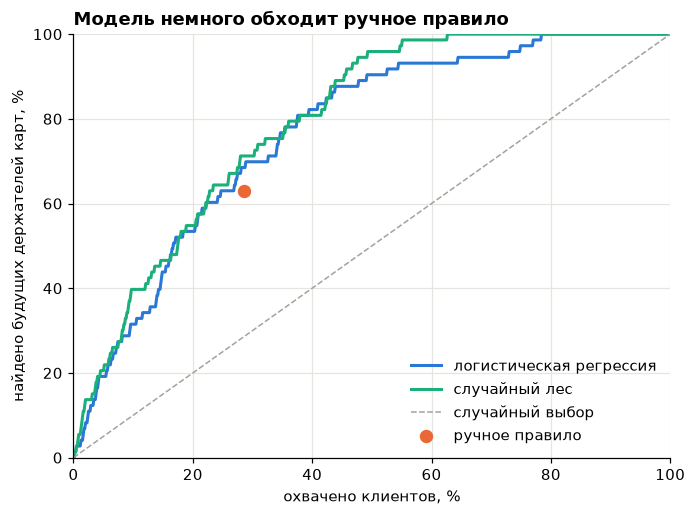

логистическая регрессия: топ-20% клиентов дают 53% будущих держателей
случайный лес: топ-20% клиентов дают 55% будущих держателей


In [16]:
best_name = max(results, key=lambda k: roc_auc_score(y_test, results[k]))

fig, ax = plt.subplots(figsize=(7, 5))
for name, proba, color in [("логистическая регрессия", results["логистическая регрессия"], CARD),
                           ("случайный лес", results["случайный лес"], "#1baf7a")]:
    order = np.argsort(-proba)
    captured = np.cumsum(y_test.values[order]) / y_test.sum()
    share = np.arange(1, len(order) + 1) / len(order)
    ax.plot(share * 100, captured * 100, color=color, linewidth=2, label=name)

ax.plot([0, 100], [0, 100], color="#a3a29d", linestyle="--", linewidth=1, label="случайный выбор")

# точка ручного правила
ax.scatter(n / len(X_test) * 100, y_test[rule].sum() / y_test.sum() * 100,
           s=60, color=NO_CARD, zorder=3, label="ручное правило")

ax.set_xlabel("охвачено клиентов, %")
ax.set_ylabel("найдено будущих держателей карт, %")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.grid(True, color="#e5e4e0")
ax.set_title("Модель немного обходит ручное правило", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
fig.savefig(IMG + "03_gain_curve.png")
plt.show()

# сколько находим, если охватить 20% клиентов с лучшим скором
for name, proba in results.items():
    top20 = pd.Series(proba, index=X_test.index).nlargest(int(len(X_test) * 0.2)).index
    print(f"{name}: топ-20% клиентов дают {y_test[top20].sum() / y_test.sum():.0%} будущих держателей")

## 7. Какие признаки важнее всего

Для случайного леса считаю permutation importance на тестовой выборке: перемешиваю один признак и смотрю, насколько падает ROC-AUC. Чем сильнее падение, тем важнее признак. Это честнее встроенной важности леса, которая завышает признаки с большим числом уникальных значений.

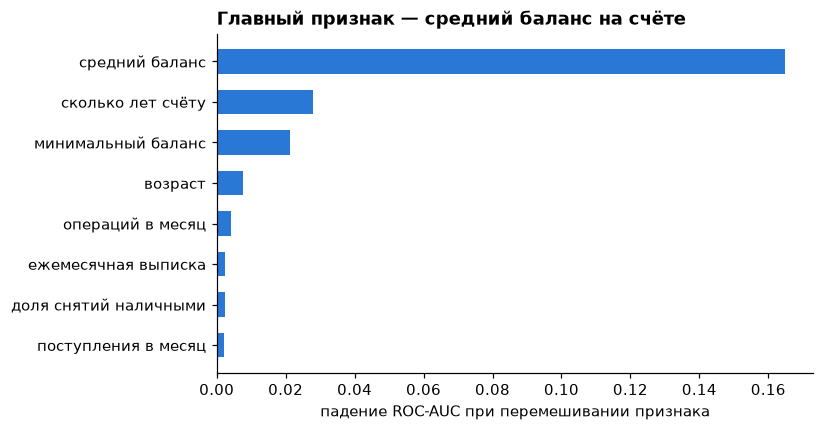

avg_balance           0.1648
account_years         0.0279
min_balance           0.0214
age                   0.0077
trans_per_month       0.0043
monthly_statement     0.0024
cash_share            0.0024
income_per_month      0.0023
district_salary       0.0018
gets_pension          0.0004
district_urban_pct    0.0004
is_female             0.0001
pays_household        0.0000
has_loan             -0.0002
has_disponent        -0.0004
dtype: float64

In [17]:
rf = models["случайный лес"]
imp = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=42, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

# подписи по-русски для графика
LABELS = {
    "avg_balance": "средний баланс", "account_years": "сколько лет счёту", "min_balance": "минимальный баланс",
    "age": "возраст", "trans_per_month": "операций в месяц", "monthly_statement": "ежемесячная выписка",
    "cash_share": "доля снятий наличными", "income_per_month": "поступления в месяц",
    "district_salary": "зарплата в районе", "gets_pension": "получает пенсию",
}
top = importance.tail(8)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([LABELS.get(f, f) for f in top.index], top.values, color=CARD, height=0.6)
ax.set_xlabel("падение ROC-AUC при перемешивании признака")
ax.set_title("Главный признак — средний баланс на счёте", loc="left", fontweight="bold")
fig.savefig(IMG + "04_importance.png")
plt.show()

importance.sort_values(ascending=False).round(4)

In [18]:
# коэффициенты логистической регрессии: знак показывает направление влияния
# признаки стандартизованы, поэтому коэффициенты можно сравнивать между собой
lr = models["логистическая регрессия"]
coefs = pd.Series(lr[-1].coef_[0], index=FEATURES).sort_values()
coefs.round(3)

income_per_month     -0.813
account_years        -0.601
gets_pension         -0.377
min_balance          -0.272
district_urban_pct   -0.065
trans_per_month      -0.047
has_disponent        -0.043
age                  -0.009
cash_share            0.014
is_female             0.028
monthly_statement     0.117
pays_household        0.125
has_loan              0.265
district_salary       0.309
avg_balance           2.024
dtype: float64

Коэффициенты нужно читать аккуратно. У поступлений коэффициент отрицательный, хотя по медианам будущие держатели карт получают вдвое больше. Это потому, что поступления и баланс сильно связаны между собой: модель уже учла деньги через баланс, и поступления лишь немного корректируют результат. Поэтому по коэффициентам признаки, связанные друг с другом, отдельно не интерпретирую, а для важности смотрю permutation importance выше.

## Выводы

- **Кто оформляет карту.** Уже за год до оформления будущие держатели карт выделяются: медианные поступления у них около 21.7 тыс. в месяц против 10.6 тыс. у остальных, и они моложе (38.8 против 43.9 лет). Клиенты 65+ почти не оформляют карту (1.9%). Это сходится с выводом SQL-проекта: карту берут клиенты, которые уже обеспечены.
- **Модель работает заметно лучше случайного выбора.** ROC-AUC на тесте 0.82 у случайного леса и 0.80 у логистической регрессии. Если предложить карту 20% клиентов с самым высоким скором, мы охватим больше половины будущих держателей карт (53–55%), а при случайном выборе только 20%.
- **Главный признак — средний баланс.** Без него ROC-AUC падает сильнее всего. Дальше идут «возраст» счёта (более новые счета чаще получают карту) и минимальный баланс.
- **Ручное правило уже неплохое.** При одинаковом охвате (227 клиентов теста) правило находит 46 будущих держателей, а случайный лес — 52 (63% против 71% от всех держателей). Модель лучше, но не в разы: простое правило по поступлениям и балансу ловит основную часть сигнала. Плюс модели в том, что она ранжирует клиентов, и можно выбрать любой охват под бюджет, а не только один порог.

**Ограничения.** В тесте всего 73 будущих держателя карт, поэтому разница в 6 клиентов между моделью и правилом может быть случайной. Модель предсказывает, кто оформит карту сам, а не кто оформит её после предложения банка, поэтому эффект от рассылки всё равно нужно проверять A/B-тестом. И это данные 1990-х: сами признаки и их влияние в современном банке будут другими, переносится подход, а не цифры.

**Что можно сделать дальше:** подобрать гиперпараметры леса, попробовать градиентный бустинг, проверить, насколько стабилен результат на разных разбиениях.